# 02. Churn: прогноз оттока клиентов SuperApp

**Цель.** Найти клиентов, которые с высокой вероятностью перестанут совершать успешные транзакции в ближайшие 30 дней, чтобы вовремя запустить кампанию удержания.

**Как устроено.**
1. Чистим транзакции (успешные статусы, выбросы).
2. Определяем churn: клиент был активен за 60 дней до даты отсечки и не совершил ни одной успешной транзакции в следующие 30 дней.
3. Считаем признаки **только по данным до отсечки** (без утечки из будущего).
4. Сравниваем Logistic Regression (базовая), LightGBM и CatBoost.
5. Проверяем качество на **другом временном срезе** (out-of-time), а не только на случайной части.
6. Объясняем модель через SHAP и переводим в бизнес-решение (кого и сколько контактировать).

**Допущения (проверь и поправь под себя):**
- Успешными считаем статусы `Успешные`, `AUSR0401`, `AUSR0402`. Остальные (`RESP...`) считаем отказами и ошибками.
- Суммы берём по модулю и обрезаем выбросы по 99,9-му процентилю.
- `customer_id` в таблице пользователей не уникален (до 3 записей на id с разными атрибутами), поэтому атрибуты пользователя считаем ненадёжными и отдельно проверяем, меняют ли они результат.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import duckdb
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import roc_auc_score, precision_score, recall_score, f1_score
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

SEED = 42
PROJECT_ROOT = Path.cwd().parent
DATA_DIR = PROJECT_ROOT / "data" / "raw"

TX_FILE = DATA_DIR / "SAPP транзакции.csv"
USERS_FILE = DATA_DIR / "SAPP пользователи.csv"

SUCCESS_STATUSES = ("Успешные", "AUSR0401", "AUSR0402")
LOOKBACK_DAYS = 60     # окно, в котором клиент должен быть активен
HORIZON_DAYS = 30      # горизонт: нет транзакций в следующие 30 дней = churn

con = duckdb.connect()
con.execute("SET memory_limit = '2GB'")
con.execute("SET threads = 2")
print("OK:", TX_FILE.exists(), USERS_FILE.exists())

OK: True True


## 1. Очистка транзакций

Читаем только нужные столбцы, оставляем успешные операции и обрезаем выбросы (в данных есть сумма порядка миллиардов при типичных тратах в десятки тысяч).

In [2]:
status_list = ", ".join(f"'{s}'" for s in SUCCESS_STATUSES)

con.execute(f"""
    CREATE OR REPLACE TABLE tx_raw AS
    SELECT
        CAST(customer_id AS BIGINT)        AS customer_id,
        CAST(transaction_date AS DATE)     AS d,
        operation_type,
        ABS(CAST(transaction_sum AS DOUBLE)) AS amt,
        terminal_type
    FROM read_csv_auto('{TX_FILE.as_posix()}')
    WHERE transaction_status IN ({status_list})
      AND customer_id IS NOT NULL
""")

cap = con.execute("SELECT quantile_cont(amt, 0.999) FROM tx_raw").fetchone()[0]
print(f"Порог выбросов (99.9-й процентиль): {cap:,.0f}")

con.execute(f"""
    CREATE OR REPLACE TABLE tx AS
    SELECT customer_id, d, operation_type, LEAST(amt, {cap}) AS amt, terminal_type
    FROM tx_raw
""")

print(con.execute("""
    SELECT COUNT(*) AS rows, COUNT(DISTINCT customer_id) AS customers,
           MIN(d) AS first_day, MAX(d) AS last_day
    FROM tx
""").df())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Порог выбросов (99.9-й процентиль): 1,398,333
      rows  customers  first_day   last_day
0  5466773     230783 2026-01-01 2026-05-12


## 2. Даты отсечки

Чтобы проверить модель честно, берём **два временных среза**:
- **train-срез**: отсечка на 30 дней раньше (обучаем на нём);
- **test-срез (out-of-time)**: отсечка ровно за 30 дней до конца данных (проверяем на нём).

Так мы имитируем реальную работу: модель обучена на прошлом и применяется к новому периоду.

In [3]:
last_day = pd.Timestamp(con.execute("SELECT MAX(d) FROM tx").fetchone()[0])
CUTOFF_TEST = last_day - pd.Timedelta(days=HORIZON_DAYS)
CUTOFF_TRAIN = CUTOFF_TEST - pd.Timedelta(days=HORIZON_DAYS)
print("Последний день данных:", last_day.date())
print("Отсечка train:", CUTOFF_TRAIN.date(), "| Отсечка test:", CUTOFF_TEST.date())

Последний день данных: 2026-05-12
Отсечка train: 2026-03-13 | Отсечка test: 2026-04-12


## 3. Признаки и целевая переменная

Все признаки считаются по данным **до** отсечки (`d <= cutoff`), целевая переменная по следующим 30 дням. Расчёт идёт SQL-запросом в DuckDB, поэтому он помещается в ограниченную память.

In [4]:
def build_dataset(cutoff: pd.Timestamp) -> pd.DataFrame:
    c = cutoff.strftime("%Y-%m-%d")
    q = f"""
    WITH base AS (
        SELECT DISTINCT customer_id
        FROM tx
        WHERE d <= DATE '{c}' AND d > DATE '{c}' - {LOOKBACK_DAYS}
    ),
    f AS (
        SELECT
            t.customer_id,
            date_diff('day', MAX(d), DATE '{c}')                       AS recency_days,
            date_diff('day', MIN(d), DATE '{c}')                       AS tenure_days,
            COUNT(*)                                                    AS n_tx,
            COUNT(DISTINCT d)                                           AS n_active_days,
            COUNT(*) FILTER (WHERE d > DATE '{c}' - 7)                  AS n_tx_7d,
            COUNT(*) FILTER (WHERE d > DATE '{c}' - 14)                 AS n_tx_14d,
            COUNT(*) FILTER (WHERE d > DATE '{c}' - 30)                 AS n_tx_30d,
            COUNT(*) FILTER (WHERE d <= DATE '{c}' - 30
                               AND d >  DATE '{c}' - 60)                AS n_tx_prev30d,
            COUNT(DISTINCT d) FILTER (WHERE d > DATE '{c}' - 30)        AS active_days_30d,
            COALESCE(SUM(amt) FILTER (WHERE d > DATE '{c}' - 30), 0)    AS sum_amt_30d,
            AVG(amt)                                                    AS avg_amt,
            AVG((operation_type = 'Purchase')::INT)                     AS share_purchase,
            AVG((operation_type = 'P2P Debit')::INT)                    AS share_p2p_debit,
            AVG((operation_type = 'P2P Credit')::INT)                   AS share_p2p_credit,
            AVG((operation_type = 'ATM Cash withdrawal')::INT)          AS share_atm,
            AVG((terminal_type = 'ePOS')::INT)                          AS share_epos
        FROM tx t
        JOIN base b USING (customer_id)
        WHERE t.d <= DATE '{c}'
        GROUP BY t.customer_id
    ),
    future AS (
        SELECT DISTINCT customer_id
        FROM tx
        WHERE d > DATE '{c}' AND d <= DATE '{c}' + {HORIZON_DAYS}
    )
    SELECT f.*, (future.customer_id IS NULL)::INT AS churn
    FROM f LEFT JOIN future USING (customer_id)
    """
    df = con.execute(q).df()
    df["ratio_30d_vs_prev30d"] = df["n_tx_30d"] / (df["n_tx_prev30d"] + 1)
    df["tx_per_active_day"] = df["n_tx"] / df["n_active_days"].clip(lower=1)
    return df

train_df = build_dataset(CUTOFF_TRAIN)
test_df = build_dataset(CUTOFF_TEST)

for name, d in [("train", train_df), ("test", test_df)]:
    print(f"{name}: {len(d):,} клиентов, доля churn = {d['churn'].mean():.3f}")
train_df.head()

train: 127,745 клиентов, доля churn = 0.406
test: 163,324 клиентов, доля churn = 0.410


,customer_id,recency_days,tenure_days,n_tx,n_active_days,n_tx_7d,n_tx_14d,n_tx_30d,n_tx_prev30d,active_days_30d,sum_amt_30d,avg_amt,share_purchase,share_p2p_debit,share_p2p_credit,share_atm,share_epos,churn,ratio_30d_vs_prev30d,tx_per_active_day
0,3825714,0,62,164,47,22,55,114,42,27,10810105.50,97584.530488,0.451220,0.457317,0.067073,0.0,0.524390,0,2.651163,3.489362
1,4252868,0,2,3,2,3,3,3,0,2,1597917.00,532639.000000,0.000000,0.333333,0.666667,0.0,1.000000,0,3.000000,1.500000
2,4062534,0,9,40,9,28,40,40,0,9,3817897.11,95447.427750,0.950000,0.025000,0.025000,0.0,0.128205,0,40.000000,4.444444
3,4125398,5,13,3,2,2,3,3,0,2,248001.00,82667.000000,0.666667,0.000000,0.333333,0.0,0.333333,0,3.000000,1.500000
4,3800982,0,64,262,58,14,34,99,152,26,9975423.69,103447.672099,0.847328,0.106870,0.041985,0.0,0.472222,0,0.647059,4.517241


## 4. Атрибуты пользователей (с осторожностью)

В таблице пользователей один `customer_id` встречается до 3 раз с разными городом, возрастом и датой регистрации. Правило: берём запись с **самой ранней датой регистрации**. Затем проверяем, сколько эти признаки дают модели, и если мало, то не опираемся на них.

In [5]:
users = con.execute(f"""
    SELECT
        CAST(customer_id AS BIGINT)                  AS customer_id,
        arg_min(customer_age, reg_date)              AS age,
        arg_min((gender = 'M')::INT, reg_date)       AS is_male,
        COUNT(*)                                     AS n_user_records
    FROM read_csv_auto('{USERS_FILE.as_posix()}')
    GROUP BY 1
""").df()

train_u = train_df.merge(users.drop(columns="n_user_records"), on="customer_id", how="left")
test_u = test_df.merge(users.drop(columns="n_user_records"), on="customer_id", how="left")
print("Доля клиентов без записи в users:", round(train_u["age"].isna().mean(), 4))

Доля клиентов без записи в users: 0.0


## 5. Модели и метрики

Сравниваем три модели на **out-of-time** срезе. Основные метрики: AUC-ROC, Precision, Recall, F1 (порог 0,5), а также Precision и Recall среди 20% клиентов с наибольшим риском, потому что в реальной кампании связаться со всеми невозможно.

In [6]:
BEHAV = [c for c in train_df.columns if c not in ("customer_id", "churn")]
ATTR = ["age", "is_male"]

def metrics(y, p, top=0.20):
    pred = (p >= 0.5).astype(int)
    k = int(len(p) * top)
    idx = np.argsort(-p)[:k]
    return {
        "AUC": roc_auc_score(y, p),
        "Precision@0.5": precision_score(y, pred),
        "Recall@0.5": recall_score(y, pred),
        "F1@0.5": f1_score(y, pred),
        "Precision@top20%": y.values[idx].mean(),
        "Recall@top20%": y.values[idx].sum() / y.sum(),
    }

def make_models():
    return {
        "LogisticRegression": make_pipeline(
            SimpleImputer(strategy="median"), StandardScaler(),
            LogisticRegression(max_iter=1000)),
        "LightGBM": LGBMClassifier(
            n_estimators=400, learning_rate=0.05, num_leaves=31,
            subsample=0.8, colsample_bytree=0.8, random_state=SEED, verbose=-1),
        "CatBoost": CatBoostClassifier(
            iterations=400, learning_rate=0.08, depth=6,
            random_seed=SEED, verbose=0, thread_count=2),
    }

def log_for_linear(X):
    X = X.copy()
    for c in X.columns:
        if X[c].min() >= 0 and X[c].max() > 50:
            X[c] = np.log1p(X[c])
    return X

def fit_eval(features, tr, te):
    res, preds, fitted = {}, {}, {}
    for name, model in make_models().items():
        Xtr, Xte = tr[features], te[features]
        if name == "LogisticRegression":
            Xtr, Xte = log_for_linear(Xtr), log_for_linear(Xte)
        model.fit(Xtr, tr["churn"])
        p = model.predict_proba(Xte)[:, 1]
        res[name] = metrics(te["churn"], p)
        preds[name], fitted[name] = p, model
    return pd.DataFrame(res).T.round(3), preds, fitted

results, preds, fitted = fit_eval(BEHAV, train_u, test_u)
results

,AUC,Precision@0.5,Recall@0.5,F1@0.5,Precision@top20%,Recall@top20%
LogisticRegression,0.815,0.684,0.663,0.674,0.778,0.380
LightGBM,0.827,0.697,0.660,0.678,0.802,0.392
CatBoost,0.827,0.697,0.661,0.679,0.804,0.392


## 6. Влияют ли атрибуты пользователей?

Если AUC почти не меняется при добавлении возраста и пола, то ненадёжность таблицы пользователей не угрожает выводам.

In [7]:
res_attr, _, _ = fit_eval(BEHAV + ATTR, train_u, test_u)
cmp = pd.DataFrame({
    "AUC без атрибутов": results["AUC"],
    "AUC с атрибутами": res_attr["AUC"],
})
cmp["Разница"] = (cmp["AUC с атрибутами"] - cmp["AUC без атрибутов"]).round(3)
cmp

,AUC без атрибутов,AUC с атрибутами,Разница
LogisticRegression,0.815,0.816,0.001
LightGBM,0.827,0.827,0.000
CatBoost,0.827,0.827,0.000


## 7. Lift по децилям

Сортируем клиентов теста по риску и делим на 10 равных групп. Если в верхнем дециле отток в разы выше среднего, модель действительно полезна для кампании.

In [8]:
best_name = results["AUC"].idxmax()
print("Лучшая модель по AUC:", best_name)

p = preds[best_name]
d = pd.DataFrame({"p": p, "churn": test_u["churn"].values})
d["decile"] = 10 - pd.qcut(d["p"].rank(method="first"), 10, labels=False)  # 1 = самый рискованный
base_rate = d["churn"].mean()
lift = (d.groupby("decile")
          .agg(clients=("churn", "size"), churn_rate=("churn", "mean"))
          .assign(lift=lambda x: x["churn_rate"] / base_rate)
          .round(3))
lift["cum_churners_share"] = (d.groupby("decile")["churn"].sum().cumsum()
                              / d["churn"].sum()).round(3)
print(f"Средняя доля churn: {base_rate:.3f}")
lift

Лучшая модель по AUC: LightGBM
Средняя доля churn: 0.410


,clients,churn_rate,lift,cum_churners_share
decile,,,,
1,16333,0.848,2.070,0.207
2,16332,0.757,1.847,0.392
3,16332,0.622,1.518,0.543
4,16333,0.538,1.312,0.675
5,16332,0.455,1.110,0.786
6,16332,0.379,0.925,0.878
7,16333,0.278,0.678,0.946
8,16332,0.157,0.382,0.984
9,16332,0.055,0.135,0.998


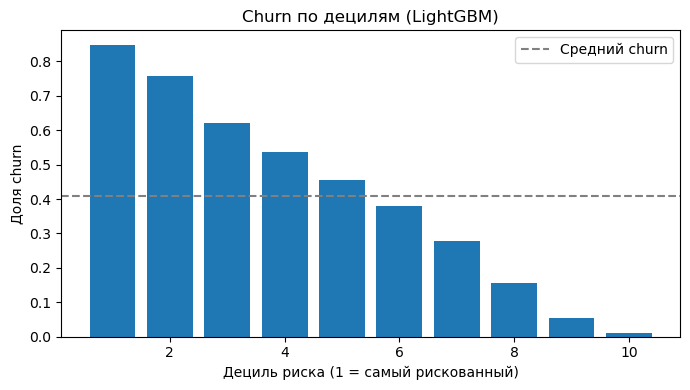

In [9]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(lift.index, lift["churn_rate"])
ax.axhline(base_rate, linestyle="--", color="gray", label="Средний churn")
ax.set_xlabel("Дециль риска (1 = самый рискованный)")
ax.set_ylabel("Доля churn")
ax.set_title(f"Churn по децилям ({best_name})")
ax.legend()
plt.tight_layout()
plt.show()

## 8. Объяснимость: SHAP

Показывает, какие признаки сильнее всего двигают риск и в какую сторону.

d:\Anaconda3\envs\dl\lib\site-packages\shap\explainers\_tree.py:586: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


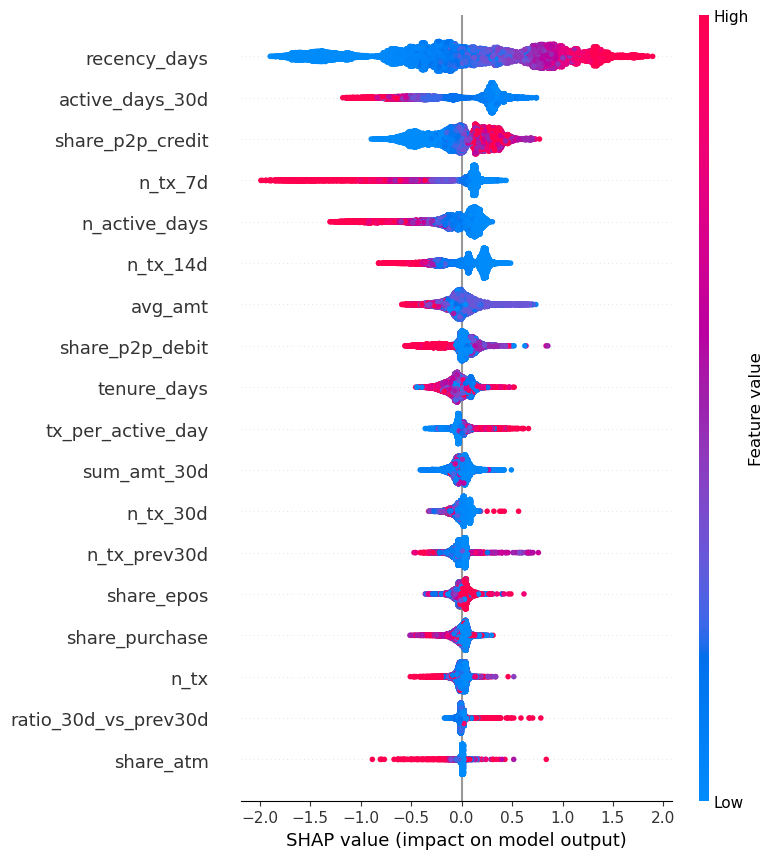

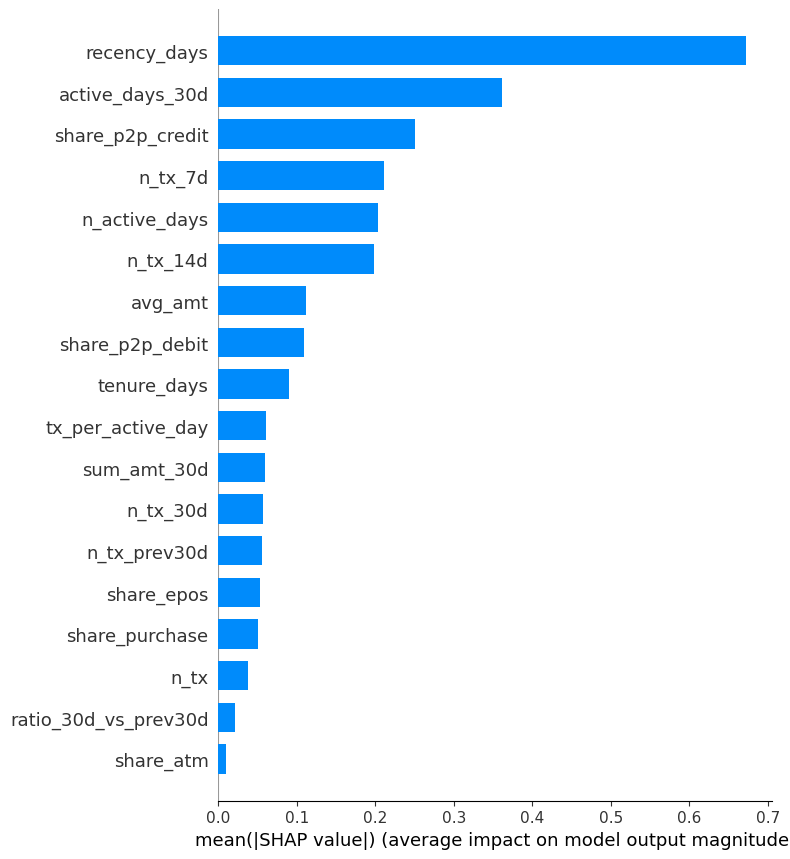

In [10]:
import shap

lgb_model = fitted["LightGBM"]
sample = test_u[BEHAV].sample(min(20000, len(test_u)), random_state=SEED)
explainer = shap.TreeExplainer(lgb_model)
sv = explainer.shap_values(sample)
sv = sv[1] if isinstance(sv, list) else sv

shap.summary_plot(sv, sample, show=False)
plt.tight_layout()
plt.show()

shap.summary_plot(sv, sample, plot_type="bar", show=False)
plt.tight_layout()
plt.show()

## 9. Бизнес-применение

Сколько клиентов контактировать и что это даст. **Параметры ниже это допущения-заглушки**, подставь реальные значения (стоимость контакта, ценность клиента, успешность удержания) или обоснуй их на собеседовании как гипотезы, которые проверит A/B-тест.

In [11]:
TOP_SHARE = 0.20            # контактируем 20% самых рискованных
COST_PER_CONTACT = 150      # допущение, тенге
RETENTION_SUCCESS = 0.10    # допущение: доля уходящих, которых удаётся удержать
VALUE_PER_SAVED = 15000     # допущение: ценность удержанного клиента, тенге

n = len(d)
k = int(n * TOP_SHARE)
top = d.sort_values("p", ascending=False).head(k)

contacted = k
true_churners = int(top["churn"].sum())
saved = true_churners * RETENTION_SUCCESS
cost = contacted * COST_PER_CONTACT
gain = saved * VALUE_PER_SAVED

print(f"Контактируем: {contacted:,} клиентов ({TOP_SHARE:.0%} базы)")
print(f"Из них реально уходящих: {true_churners:,} (precision {true_churners/contacted:.1%})")
print(f"Охват всех уходящих (recall): {true_churners / d['churn'].sum():.1%}")
print(f"Ожидаемо удержим: {saved:,.0f} клиентов")
print(f"Затраты: {cost:,.0f} тг | Выгода: {gain:,.0f} тг | Результат: {gain - cost:,.0f} тг")

Контактируем: 32,664 клиентов (20% базы)
Из них реально уходящих: 26,212 (precision 80.2%)
Охват всех уходящих (recall): 39.2%
Ожидаемо удержим: 2,621 клиентов
Затраты: 4,899,600 тг | Выгода: 39,318,000 тг | Результат: 34,418,400 тг


## 10. Выводы (заполни своими словами по результатам)

1. **Качество модели:** AUC на out-of-time срезе = ... Лучшая модель: ...
2. **Что предсказывает отток:** по SHAP главные факторы: ...
3. **Lift:** в верхнем дециле churn ... против среднего ... (в ... раза выше).
4. **Атрибуты пользователей:** добавление возраста и пола меняет AUC на ..., поэтому ...
5. **Рекомендация бизнесу:** контактировать верхние 20% по риску, сегментировать по причинам (падение частоты, смена типа операций), проверить эффект через A/B-тест с контрольной группой.
6. **Ограничения:** период данных около 4,5 месяцев; `customer_id` в таблице пользователей не уникален; churn определён поведенчески (нет транзакций), а не по факту закрытия аккаунта; причинность не доказана.